In [31]:
from collections import deque

def encontrar_componentes_bfs(grafo):
    visitados = set()
    componentes = []

    for pixel_inicial in grafo:
        if pixel_inicial not in visitados:
            # Inicia uma nova componente conexa
            pixels_componente = []
            fila = deque([pixel_inicial])
            visitados.add(pixel_inicial)

            while fila:
                u = fila.popleft()
                pixels_componente.append(u)

                for v in grafo[u]:
                    if v not in visitados:
                        visitados.add(v)
                        fila.append(v)

            componentes.append({
                'tamanho': len(pixels_componente),
                'pixels': pixels_componente
            })

    # Ordena da maior componente para a menor
    componentes.sort(key=lambda c: c['tamanho'], reverse=True)

    # Atribui um ID sequencial (0 = maior componente)
    for idx, comp in enumerate(componentes):
        comp['id'] = idx

    return componentes

In [32]:
componentes = encontrar_componentes_bfs(josefran_graph)

print(f"Total de componentes conexas: {len(componentes)}\n")

for comp in componentes[:10]:
    print(f"Componente {comp['id']}: {comp['tamanho']} pixels | Primeiros pixels: {comp['pixels'][:3]}")

Total de componentes conexas: 626

Componente 0: 828 pixels | Primeiros pixels: [(40, 18), (41, 18), (42, 18)]
Componente 1: 786 pixels | Primeiros pixels: [(0, 0), (1, 0), (0, 1)]
Componente 2: 400 pixels | Primeiros pixels: [(2, 24), (2, 25), (2, 26)]
Componente 3: 270 pixels | Primeiros pixels: [(18, 27), (18, 28), (19, 28)]
Componente 4: 120 pixels | Primeiros pixels: [(27, 46), (28, 46), (29, 46)]
Componente 5: 117 pixels | Primeiros pixels: [(0, 55), (1, 55), (0, 56)]
Componente 6: 84 pixels | Primeiros pixels: [(13, 52), (14, 52), (15, 52)]
Componente 7: 74 pixels | Primeiros pixels: [(0, 35), (1, 35), (0, 36)]
Componente 8: 54 pixels | Primeiros pixels: [(31, 57), (32, 57), (33, 57)]
Componente 9: 52 pixels | Primeiros pixels: [(45, 60), (46, 60), (45, 61)]


In [33]:
def visualizar_componentes_bfs(matriz_pixels, componentes, tamanho_minimo=1, seed=42):
    altura, largura = matriz_pixels.shape
    imagem_colorida = np.zeros((altura, largura, 3), dtype=np.uint8)
    rng = np.random.default_rng(seed)

    exibidas = 0
    for comp in componentes:
        if comp['tamanho'] >= tamanho_minimo:
            # Gera cor RGB entre 40 e 255 para destacar do fundo preto
            cor = rng.integers(40, 256, size=3, dtype=np.uint8)
            for i, j in comp['pixels']:
                imagem_colorida[i, j] = cor
            exibidas += 1

    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

    axes[0].imshow(matriz_pixels, cmap='gray')
    axes[0].set_title("Imagem Original (64x64)")
    axes[0].axis('off')

    axes[1].imshow(imagem_colorida)
    axes[1].set_title(f"Componentes Conexas via BFS ({exibidas}/{len(componentes)} | mín={tamanho_minimo} px)")
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()

    return imagem_colorida

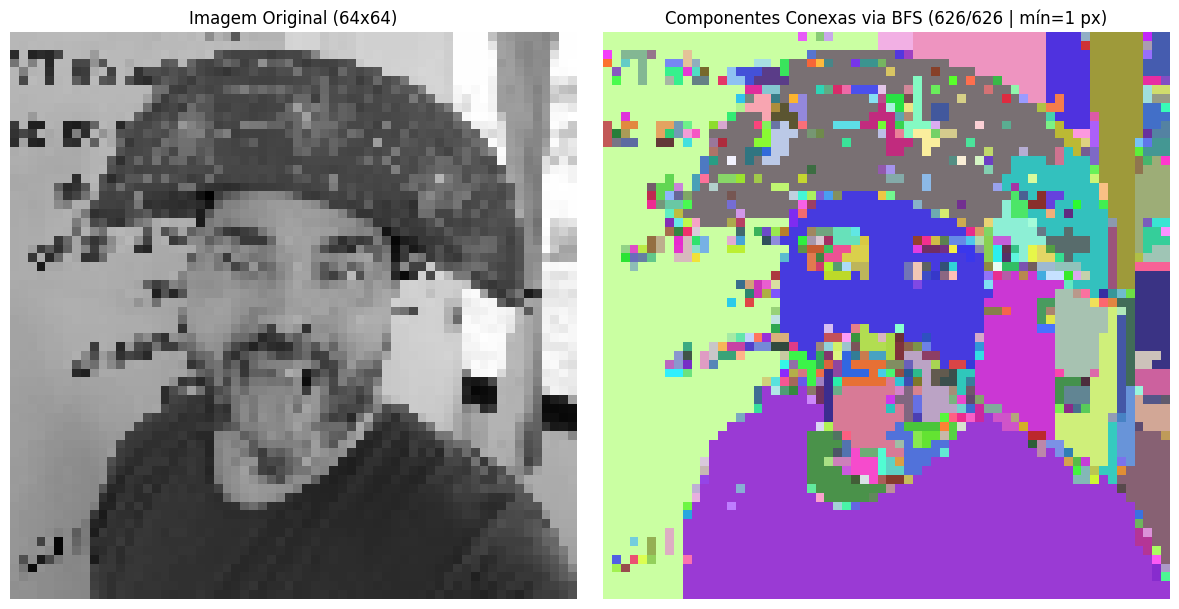

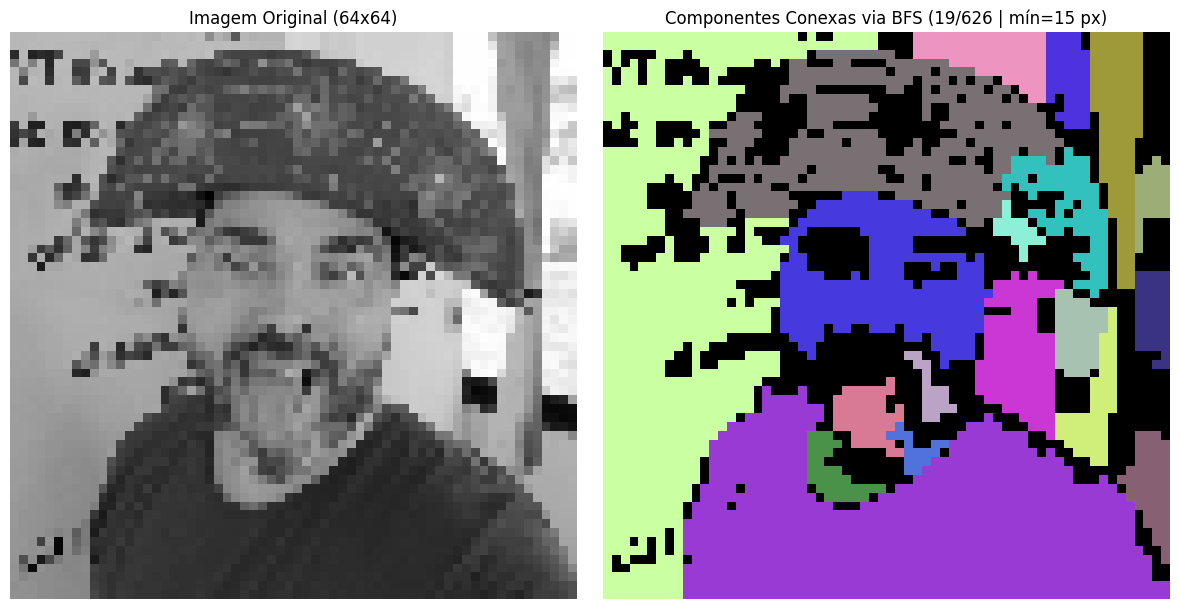

In [34]:
# Visualiza todas as componentes encontradas
_ = visualizar_componentes_bfs(josefran_image, componentes, tamanho_minimo=1)

# Filtra ruídos exibindo apenas componentes com 15 ou mais pixels
_ = visualizar_componentes_bfs(josefran_image, componentes, tamanho_minimo=15)

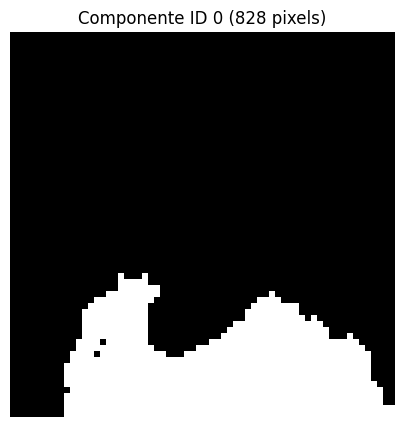

In [35]:
def visualizar_componente_unica(matriz_pixels, componente):
    mascara = np.zeros_like(matriz_pixels)
    for i, j in componente['pixels']:
        mascara[i, j] = 255

    plt.figure(figsize=(5, 5))
    plt.imshow(mascara, cmap='gray')
    plt.title(f"Componente ID {componente['id']} ({componente['tamanho']} pixels)")
    plt.axis('off')
    plt.show()

visualizar_componente_unica(josefran_image, componentes[0])